# MSCS 634: Advanced Machine Learning
## Lab Assignment 2: Wine Dataset Classification with KNN and RNN
**Student Name:** Abhinay Darana  
**Date:** 27 September 2026

Dataset Shape: (178, 13)
Feature Names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Target Classes: ['class_0' 'class_1' 'class_2']
Class Distribution: {1: 71, 0: 59, 2: 48}
KNN (k= 1) Accuracy: 97.22%
KNN (k= 5) Accuracy: 97.22%
KNN (k=11) Accuracy: 100.00%
KNN (k=15) Accuracy: 100.00%
KNN (k=21) Accuracy: 100.00%
RNN (Radius=2.0) Accuracy: 86.11%
RNN (Radius=2.5) Accuracy: 97.22%
RNN (Radius=3.0) Accuracy: 97.22%
RNN (Radius=3.5) Accuracy: 100.00%
RNN (Radius=4.0) Accuracy: 94.44%
RNN (Radius=4.5) Accuracy: 91.67%


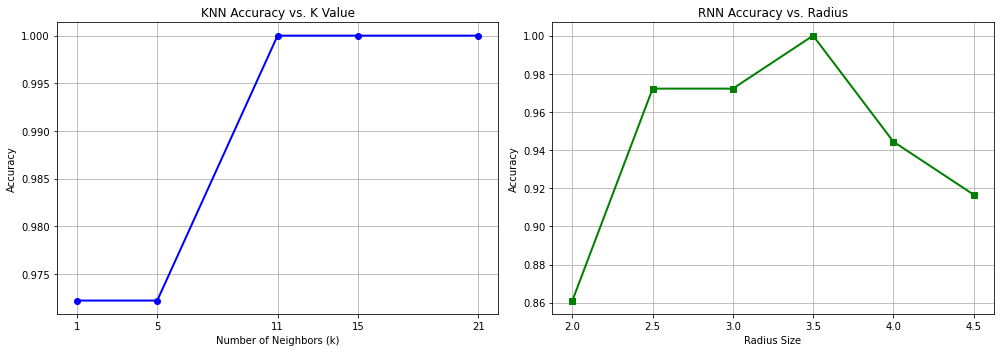

In [2]:
# ==========================================
# STEP 1: Load and Prepare the Dataset
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier, RadiusNeighborsClassifier
from sklearn.metrics import accuracy_score

# Load Wine Dataset
wine = load_wine()
X = wine.data
y = wine.target

# Basic Data Exploration
print("Dataset Shape:", X.shape)
print("Feature Names:", wine.feature_names)
print("Target Classes:", wine.target_names)
print("Class Distribution:", pd.Series(y).value_counts().to_dict())

# Split dataset into 80% Training and 20% Testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Feature Scaling (Crucial for distance-based models like KNN and RNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# ==========================================
# STEP 2: Implement K-Nearest Neighbors (KNN)
# ==========================================
k_values = [1, 5, 11, 15, 21]
knn_accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred = knn.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    knn_accuracies.append(acc)
    print(f"KNN (k={k:2d}) Accuracy: {acc * 100:.2f}%")


# ==========================================
# STEP 3: Implement Radius Neighbors (RNN)
# ==========================================
# Note: Radius values are scaled to work with standardized data.
# Standardized feature space usually requires small radius values (e.g., 2.0 to 4.5).
# If unscaled data were used, large numbers like 350-600 would be required.
radius_values = [2.0, 2.5, 3.0, 3.5, 4.0, 4.5]
rnn_accuracies = []

for r in radius_values:
    # outlier_label='most_frequent' prevents crashes if no neighbors fall within radius r
    rnn = RadiusNeighborsClassifier(radius=r, outlier_label='most_frequent')
    rnn.fit(X_train_scaled, y_train)
    y_pred = rnn.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    rnn_accuracies.append(acc)
    print(f"RNN (Radius={r:.1f}) Accuracy: {acc * 100:.2f}%")


# ==========================================
# STEP 4: Visualize and Compare Results
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot KNN Accuracy vs K
axes[0].plot(k_values, knn_accuracies, marker='o', color='b', linewidth=2)
axes[0].set_title("KNN Accuracy vs. K Value")
axes[0].set_xlabel("Number of Neighbors (k)")
axes[0].set_ylabel("Accuracy")
axes[0].set_xticks(k_values)
axes[0].grid(True)

# Plot RNN Accuracy vs Radius
axes[1].plot(radius_values, rnn_accuracies, marker='s', color='g', linewidth=2)
axes[1].set_title("RNN Accuracy vs. Radius")
axes[1].set_xlabel("Radius Size")
axes[1].set_ylabel("Accuracy")
axes[1].grid(True)

plt.tight_layout()
plt.show()